In [ ]:
from google.colab import files

uploaded = files.upload()

Saving iris (1).csv to iris (1).csv


In [3]:
import numpy as np
import pandas as pd

flowers = pd.read_csv("iris (1).csv")



x = flowers[["petal_length", "petal_width"]].to_numpy()

y = (flowers.species == "virginica").to_numpy(float)

x = np.column_stack([np.ones(len(x)), x])

theta = np.zeros(3)

for step in range(3001):

    p = 1 / (1 + np.exp(-x @ theta))

    if step % 500 == 0:
        ll = np.mean(
            y * np.log10(p) +
            (1 - y) * np.log10(1 - p)
        )

        print(f"step {step:4d} log likelihood {ll:.3f}")

    theta += 0.1 * x.T @ (y - p) / len(y)

print(f"accuracy {np.mean((p > 0.5) == (y == 1)):.2f}")

step    0 log likelihood -0.301
step  500 log likelihood -0.128
step 1000 log likelihood -0.103
step 1500 log likelihood -0.091
step 2000 log likelihood -0.084
step 2500 log likelihood -0.078
step 3000 log likelihood -0.074
accuracy 0.97


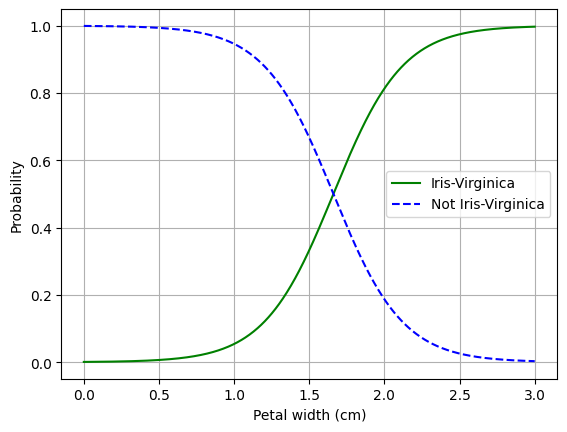

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.linear_model import LogisticRegression

# Load Iris dataset
iris = datasets.load_iris()

# Select petal width
X = iris["data"][:, 3:]

# Target: 1 = Virginica, 0 = Not Virginica
y = (iris["target"] == 2).astype(int)

# Create and train the model
log_reg = LogisticRegression()
log_reg.fit(X, y)

# Generate new data
X_new = np.linspace(0, 3, 1000).reshape(-1, 1)

# Predict probabilities
y_proba = log_reg.predict_proba(X_new)

# Plot the results
plt.plot(X_new, y_proba[:, 1], "g-", label="Iris-Virginica")
plt.plot(X_new, y_proba[:, 0], "b--", label="Not Iris-Virginica")

plt.xlabel("Petal width (cm)")
plt.ylabel("Probability")
plt.legend()
plt.grid()
plt.show()
